 # Week 2: Supervised Machine Learning Models

## Objective
The objective of this project is to implement and evaluate supervised machine learning algorithms using Scikit-learn. Both regression and classification problems will be explored.

## Datasets
1. **California Housing Dataset:** Predict median house values using regression models.
2. **Titanic Dataset:** Predict passenger survival using classification models.

## Algorithms
- Linear Regression
- Logistic Regression
- Decision Tree
- Random Forest
- K-Nearest Neighbors (KNN)

## Evaluation
Regression models will be evaluated using MAE, MSE, RMSE, and R². Classification models will be evaluated using accuracy, precision, recall, F1-score, and confusion matrices.

The final objective is to compare model performance on held-out test data and explain the observed results.

### Supervised Machine Learning is a machine learning approach in which an algorithm learns a mapping between input features and a known target variable using labeled training data. The learned relationship is then used to make predictions on previously unseen data.
### Supervised learning is broadly divided into regression and classification problems. Regression predicts continuous numerical values, whereas classification predicts discrete class labels.
### In this task, regression and classification algorithms are implemented using Scikit-learn. The models are trained using training data, evaluated using appropriate performance metrics, and compared to determine their relative performance.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing

In [2]:
df_titanic = pd.read_csv("train1.csv")

In [3]:
print("Dataset loaded successfully.")
print("Dataset shape:", df_titanic.shape)

Dataset loaded successfully.
Dataset shape: (891, 12)


In [4]:
df_titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
print("First five rows:")
display(df_titanic.head())

print("Dataset information:")
df_titanic.info()

print("\nStatistical summary:")
display(df_titanic.describe(include="all").T)

print("\nData types:")
display(df_titanic.dtypes)

print("\nMissing values:")
display(df_titanic.isnull().sum())

print("\nDuplicate rows:", df_titanic.duplicated().sum())

print("\nUnique values per column:")
display(df_titanic.nunique())

First five rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292



Data types:


PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


Missing values:


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


Duplicate rows: 0

Unique values per column:


PassengerId    891
Survived         2
Pclass           3
Name           891
Sex              2
Age             88
SibSp            7
Parch            7
Ticket         681
Fare           248
Cabin          147
Embarked         3
dtype: int64

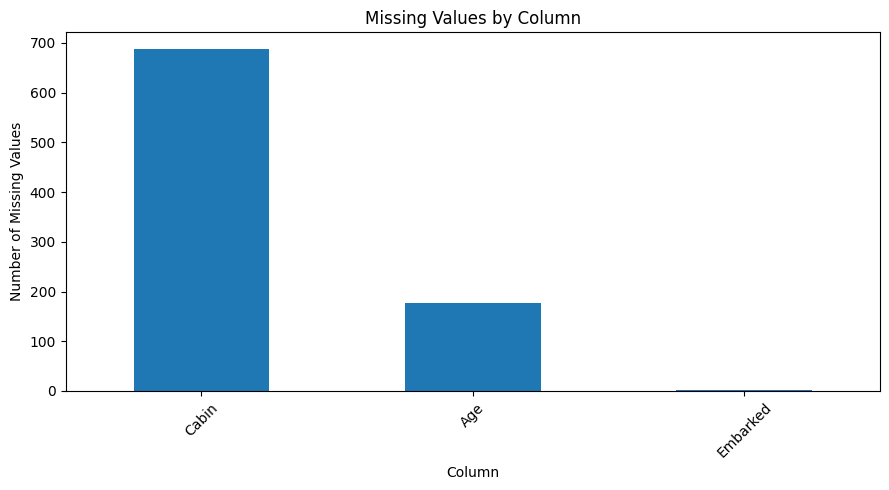

In [6]:
missing = df_titanic.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

plt.figure(figsize=(9, 5))
missing.plot(kind="bar")
plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

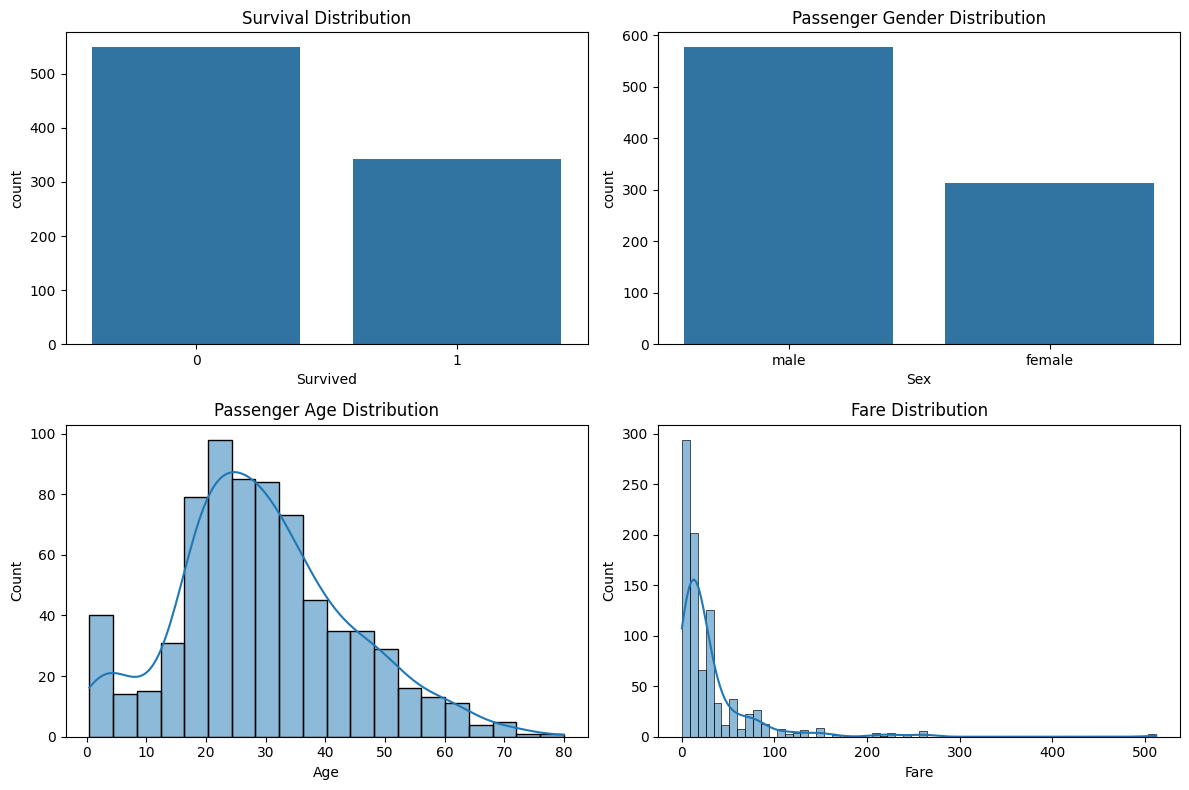

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.countplot(data=df_titanic, x="Survived", ax=axes[0, 0])
axes[0, 0].set_title("Survival Distribution")

sns.countplot(data=df_titanic, x="Sex", ax=axes[0, 1])
axes[0, 1].set_title("Passenger Gender Distribution")

sns.histplot(
    data=df_titanic,
    x="Age",
    kde=True,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Passenger Age Distribution")

sns.histplot(
    data=df_titanic,
    x="Fare",
    kde=True,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Fare Distribution")

plt.tight_layout()
plt.show()

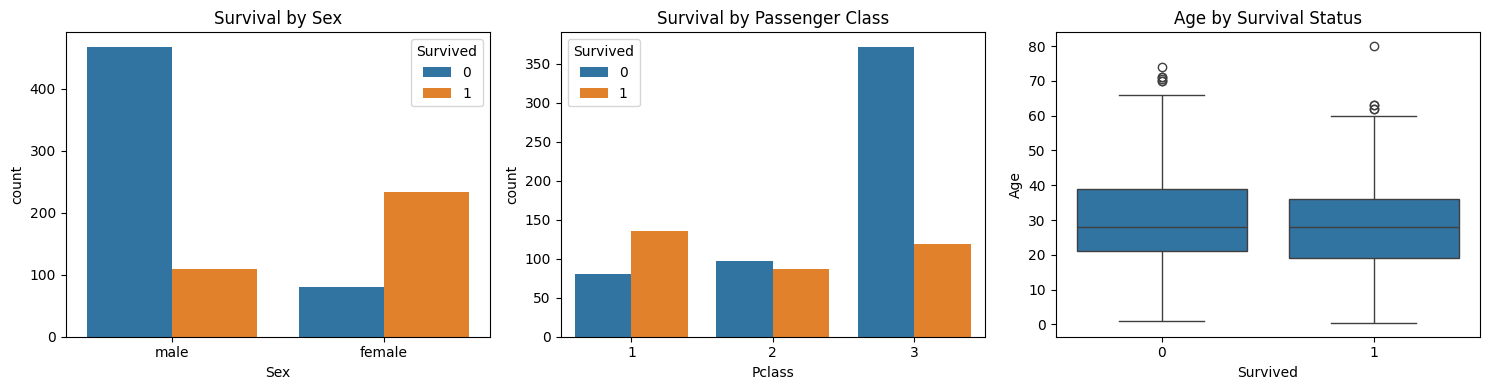

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(
    data=df_titanic,
    x="Sex",
    hue="Survived",
    ax=axes[0]
)
axes[0].set_title("Survival by Sex")

sns.countplot(
    data=df_titanic,
    x="Pclass",
    hue="Survived",
    ax=axes[1]
)
axes[1].set_title("Survival by Passenger Class")

sns.boxplot(
    data=df_titanic,
    x="Survived",
    y="Age",
    ax=axes[2]
)
axes[2].set_title("Age by Survival Status")

plt.tight_layout()
plt.show()

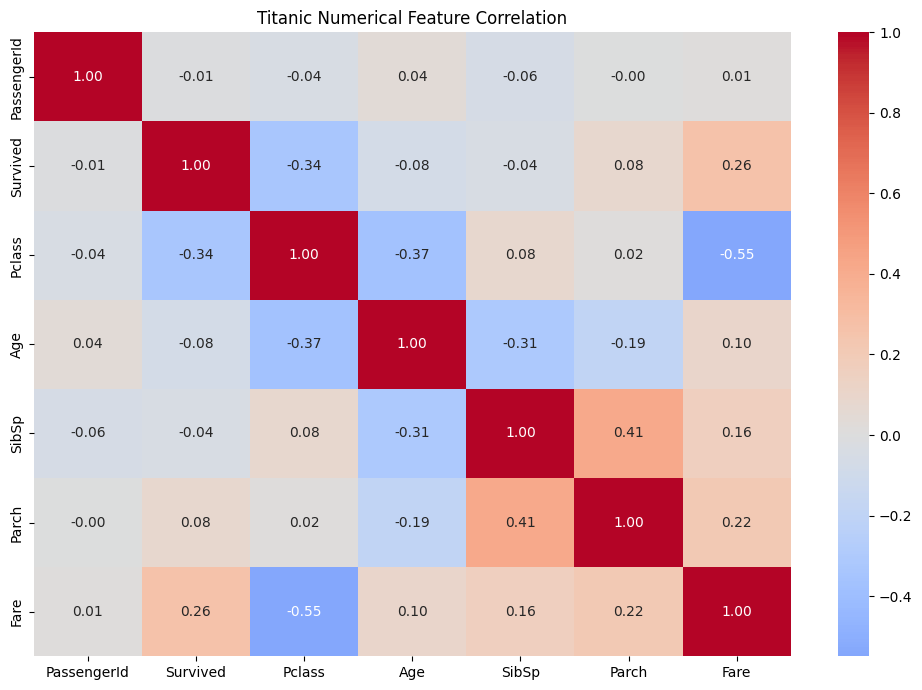

In [9]:
numeric_df = df_titanic.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Titanic Numerical Feature Correlation")
plt.tight_layout()
plt.show()

In [14]:
# Create a copy so the original dataset remains unchanged
df = df_titanic.copy()

df = df.drop_duplicates().copy()

# Separate input features (X) and target (y)
X = df.drop(
    columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"]
)

y = df["Survived"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts().sort_index())

Feature shape: (891, 7)
Target shape: (891,)

Feature columns:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

Target distribution:
Survived
0    549
1    342
Name: count, dtype: int64


In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (712, 7)
X_test: (179, 7)
y_train: (712,)
y_test: (179,)


## Handling Missing Values, Encoding and Feature Scaling

In [16]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [17]:
numeric_features = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

categorical_features = [
    "Pclass",
    "Sex",
    "Embarked"
]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Age', 'SibSp', 'Parch', 'Fare']
Categorical features: ['Pclass', 'Sex', 'Embarked']


In [18]:
# Numerical preprocessing for Logistic Regression and KNN
numeric_scaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Numerical preprocessing for Decision Tree and Random Forest
numeric_unscaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing shared by all models
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Preprocessing for scale-sensitive models
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ("num", numeric_scaled, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Preprocessing for tree-based models
preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ("num", numeric_unscaled, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipelines created successfully.")

Preprocessing pipelines created successfully.


# Model 1: Logistic Regression.

In [19]:
from sklearn.linear_model import LogisticRegression

log_model = Pipeline(steps=[
    ("preprocessor", preprocessor_scaled),
    ("model", LogisticRegression(max_iter=1000))
])

log_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test)

print("Logistic Regression trained successfully.")
print("Sample predictions:", y_pred_log[:10])
print("Actual values:     ", y_test.iloc[:10].to_numpy())

Logistic Regression trained successfully.
Sample predictions: [0 0 0 0 1 0 1 0 0 0]
Actual values:      [0 0 1 0 1 1 1 0 0 0]


# Model 2: Decision Tree Classifier

In [21]:
from sklearn.tree import DecisionTreeClassifier

dt_model = Pipeline(steps=[
    ("preprocessor", preprocessor_unscaled),
    ("model", DecisionTreeClassifier(random_state=42))
])

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree trained successfully.")
print("Sample predictions:", y_pred_dt[:10])

Decision Tree trained successfully.
Sample predictions: [0 0 0 0 1 0 1 1 0 0]


# Model 3: Random Forest Classifier.

In [22]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor_unscaled),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest trained successfully.")
print("Sample predictions:", y_pred_rf[:10])

Random Forest trained successfully.
Sample predictions: [0 0 0 0 1 0 1 1 0 0]


# Model 4: K-Nearest Neighbors Classifier.

In [23]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline(steps=[
    ("preprocessor", preprocessor_scaled),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

print("KNN trained successfully.")
print("Sample predictions:", y_pred_knn[:10])

KNN trained successfully.
Sample predictions: [0 0 0 0 1 0 1 0 0 0]


# Classification Model Evaluation

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

predictions = {
    "Logistic Regression": y_pred_log,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "KNN": y_pred_knn
}

classification_results = []

for model_name, y_pred in predictions.items():
    classification_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

classification_results_df = pd.DataFrame(
    classification_results
)

display(
    classification_results_df.round(4)
    .sort_values("F1 Score", ascending=False)
    .reset_index(drop=True)
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.8156,0.7812,0.7246,0.7519
1,Random Forest,0.8212,0.8136,0.6957,0.7500
2,KNN,0.8212,0.8136,0.6957,0.7500
3,Logistic Regression,0.8045,0.7931,0.6667,0.7244


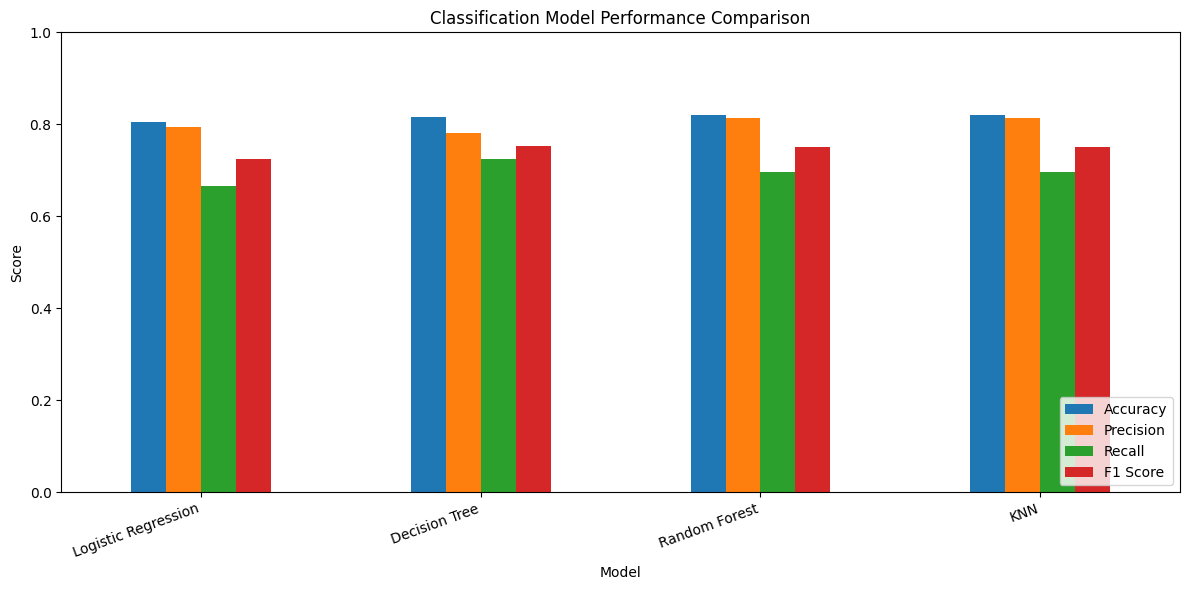

In [25]:
plot_df = classification_results_df.set_index("Model")

plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Classification Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

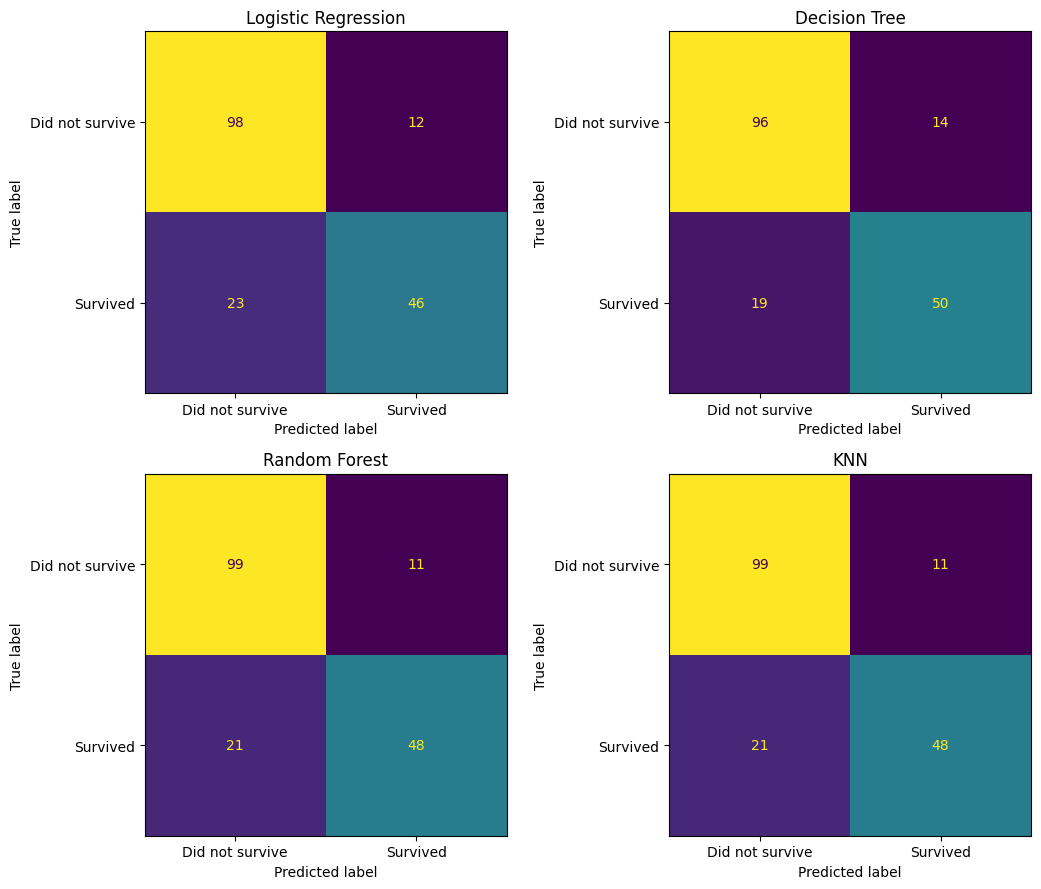

In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (model_name, y_pred) in zip(
    axes.flat, predictions.items()
):
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Did not survive", "Survived"]
    )

    disp.plot(ax=ax, values_format="d", colorbar=False)
    ax.set_title(model_name)

plt.tight_layout()
plt.show()

In [27]:
for model_name, y_pred in predictions.items():
    print(f"\n{'=' * 55}")
    print(model_name)
    print("=" * 55)

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["Did not survive", "Survived"],
        zero_division=0
    ))


Logistic Regression
                 precision    recall  f1-score   support

Did not survive       0.81      0.89      0.85       110
       Survived       0.79      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179


Decision Tree
                 precision    recall  f1-score   support

Did not survive       0.83      0.87      0.85       110
       Survived       0.78      0.72      0.75        69

       accuracy                           0.82       179
      macro avg       0.81      0.80      0.80       179
   weighted avg       0.81      0.82      0.81       179


Random Forest
                 precision    recall  f1-score   support

Did not survive       0.82      0.90      0.86       110
       Survived       0.81      0.70      0.75        69

       accuracy                           0.82       179
      macro avg       0.82   

## Classification Results and Interpretation

Four classification algorithms—Logistic Regression, Decision Tree, Random Forest, and K-Nearest Neighbors (KNN)—were trained and evaluated on the Titanic dataset.

All models used the same training and test split. Missing values were handled using training-set statistics, categorical variables were One-Hot Encoded, and numerical features were standardized for Logistic Regression and KNN.

### Model Performance

- **Best model by F1-score:** Decision Tree, with an F1-score of **0.7519**.
- **Best model by accuracy:** Random Forest and KNN, both achieving an accuracy of **0.8212 (82.12%)**.
- **Precision and recall:** The Decision Tree achieved the highest recall (0.7246), meaning it identified a larger proportion of actual survivors than the other three models. Random Forest and KNN achieved the highest precision (0.8136), meaning their positive survival predictions were more often correct. Logistic Regression had the lowest recall (0.6667) and F1-score (0.7244) among the evaluated models.
- **Confusion matrix:** The confusion matrices can be used to compare false positives and false negatives for each model. The matrix for the Decision Tree should be examined to determine whether it made more errors predicting survival or non-survival; this cannot be established from the summary metrics alone.

### Conclusion

Based on the evaluation results, the Decision Tree performed best in terms of F1-score and recall, while Random Forest and KNN achieved the highest overall accuracy. The Decision Tree may be preferable when identifying more actual survivors is important, whereas Random Forest and KNN demonstrated stronger precision in their positive predictions.

The results show that different algorithms perform differently depending on the evaluation metric. Therefore, model selection should consider the problem's objectives rather than accuracy alone. These findings are based on a single held-out test set, and further cross-validation and hyperparameter tuning could help determine whether the observed differences are consistent.

In [29]:
california = fetch_california_housing()
df =  pd.DataFrame(california.data, columns=california.feature_names)
df.to_csv("california_housing.csv", index=False)

df_housing = pd.DataFrame(
    california.data,
    columns=california.feature_names
)

df_housing["MedHouseVal"] = california.target

df_housing.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [30]:
print("Dataset shape:", df_housing.shape)

print("\nColumn names:")
print(df_housing.columns.tolist())

print("\nDataset information:")
df_housing.info()

print("\nStatistical summary:")
display(df_housing.describe())

Dataset shape: (20640, 9)

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [31]:
print("Missing values per column:")
print(df_housing.isnull().sum())

print("\nTotal missing values:", df_housing.isnull().sum().sum())

print("\nDuplicate rows:", df_housing.duplicated().sum())

Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Total missing values: 0

Duplicate rows: 0


Task was destroyed but it is pending!
task: <Task pending name='Task-182' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\dubey\AppData\Local\Programs\Python\Python313\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-183' coro=<Kernel.shell_main() running at C:\Users\dubey\AppData\Local\Programs\Python\Python313\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\dubey\AppData\Local\Programs\Python\Python313\Lib\site-packages\zmq\eventloop\zmqstream.py:563]>
C:\Users\dubey\AppData\Local\Programs\Python\Python313\Lib\site-packages\matplotlib\_api\__init__.py:79: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  tuple(none_type if tp is None else tp for tp in types))
Task was destroyed but it is pending!
task: <Task pending name='Task-183' coro=<Kernel.shell_main() running at C:\Users\dubey\AppData\Local\Programs\Python\Python313\Lib\site

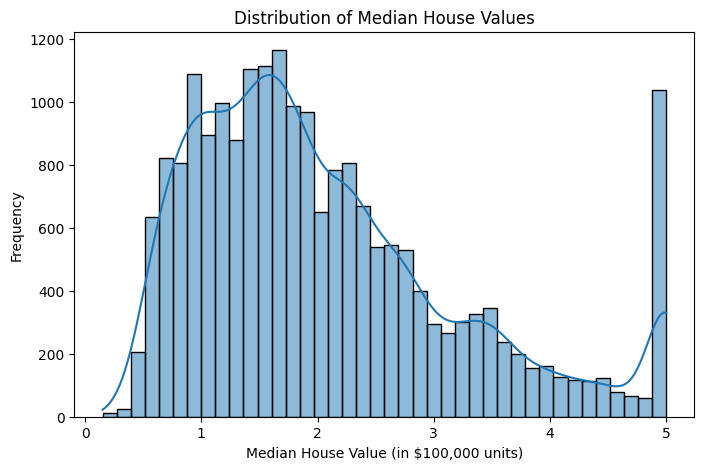

In [32]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df_housing,
    x="MedHouseVal",
    bins=40,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value (in $100,000 units)")
plt.ylabel("Frequency")
plt.show()

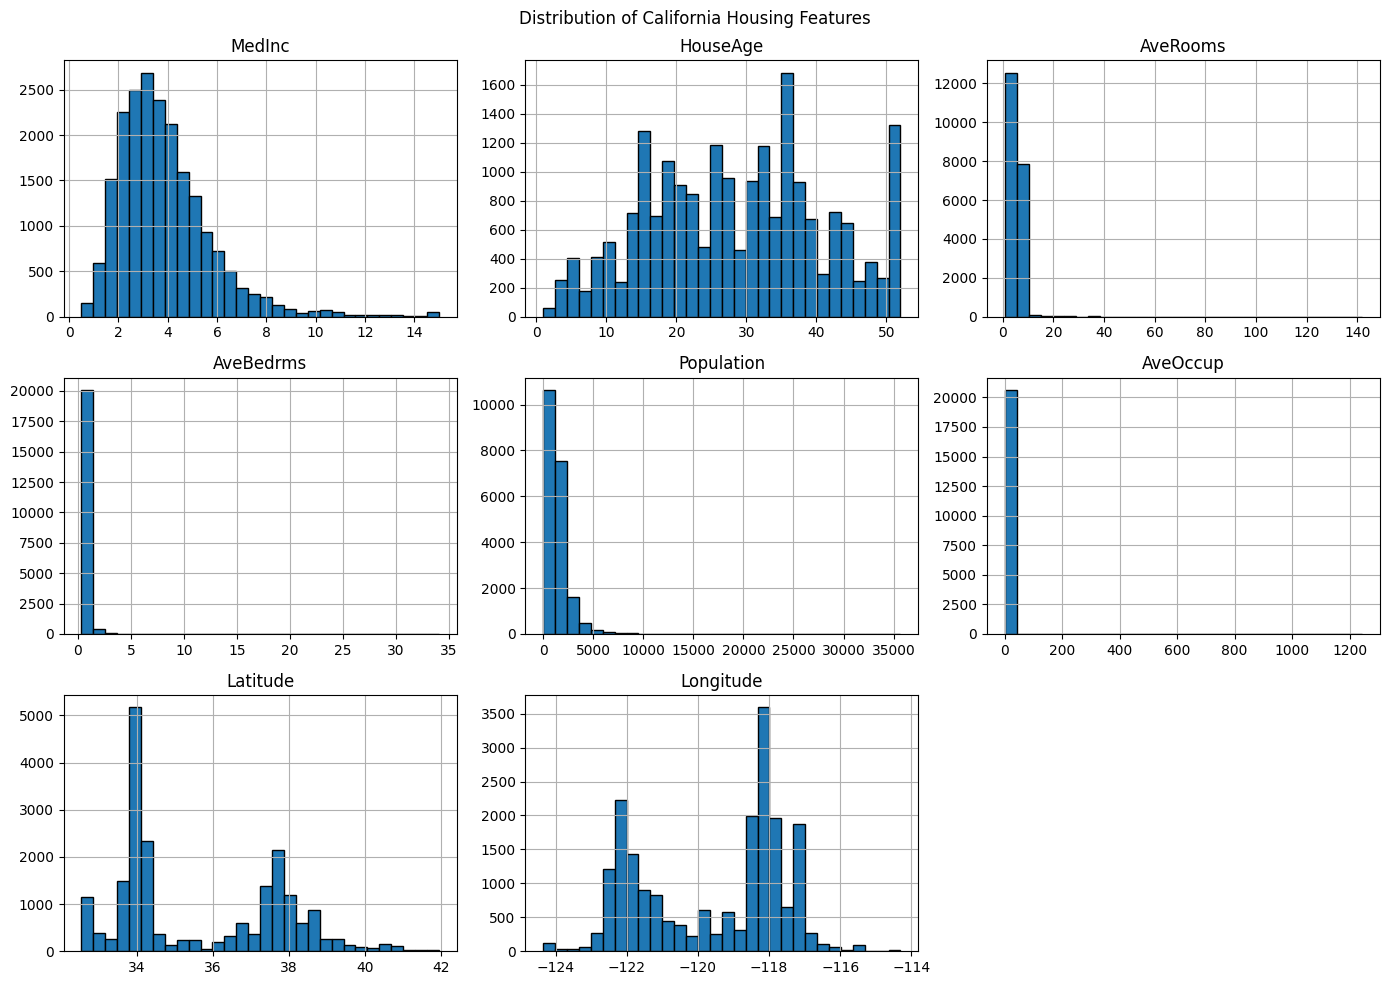

In [33]:
df_housing.drop(columns=["MedHouseVal"]).hist(
    figsize=(14, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of California Housing Features")
plt.tight_layout()
plt.show()

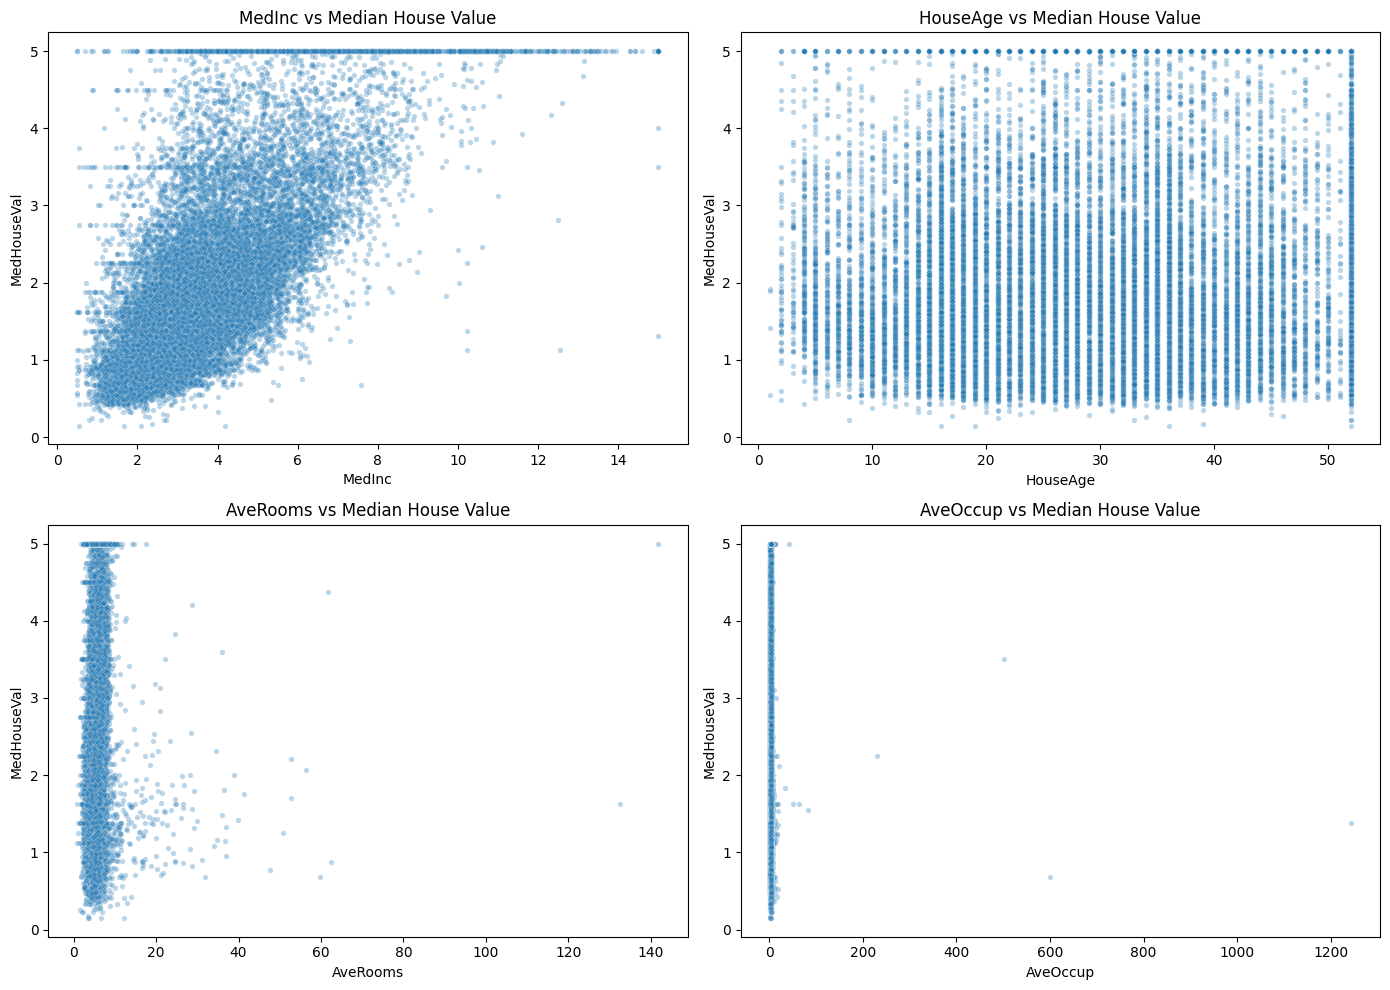

In [34]:
features_to_plot = [
    "MedInc",
    "HouseAge",
    "AveRooms",
    "AveOccup"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(features_to_plot, axes.flatten()):
    sns.scatterplot(
        data=df_housing,
        x=feature,
        y="MedHouseVal",
        alpha=0.3,
        s=15,
        ax=ax
    )

    ax.set_title(f"{feature} vs Median House Value")

plt.tight_layout()
plt.show()

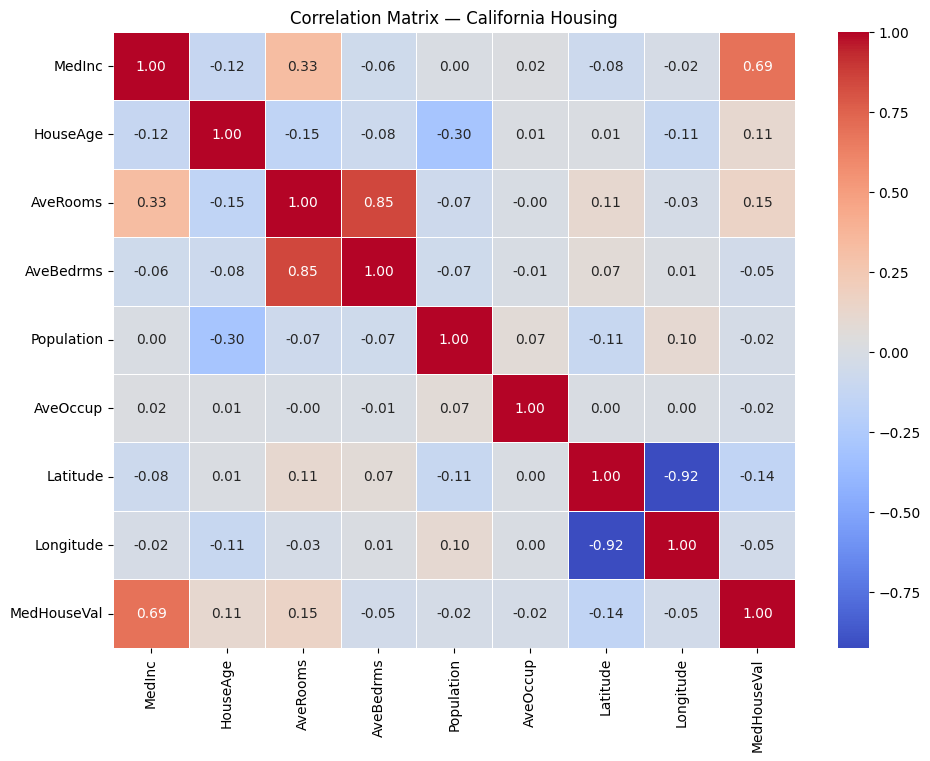

In [35]:
plt.figure(figsize=(11, 8))

correlation_matrix = df_housing.corr(numeric_only=True)

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix — California Housing")
plt.show()

In [36]:
X = df_housing.drop(columns=["MedHouseVal"])
y = df_housing["MedHouseVal"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature shape: (20640, 8)
Target shape: (20640,)

Features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)
Training targets: (16512,)
Testing targets: (4128,)


In [38]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

numeric_features = X.columns.tolist()

linear_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

tree_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Linear Regression

In [39]:
from sklearn.linear_model import LinearRegression

linear_model = Pipeline(steps=[
    ("preprocessor", linear_preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

print("Linear Regression training completed.")
print("Sample predictions:", y_pred_linear[:5])
print("Actual values:", y_test.iloc[:5].values)

Linear Regression training completed.
Sample predictions: [0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]
Actual values: [0.477   0.458   5.00001 2.186   2.78   ]


# Decision Tree Regressor

In [40]:
from sklearn.tree import DecisionTreeRegressor

dt_reg_model = Pipeline(steps=[
    ("preprocessor", tree_preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

dt_reg_model.fit(X_train, y_train)

y_pred_dt_reg = dt_reg_model.predict(X_test)

print("Decision Tree Regressor training completed.")
print("Sample predictions:", y_pred_dt_reg[:5])

Decision Tree Regressor training completed.
Sample predictions: [0.414   1.203   5.00001 2.17    2.257  ]


# Random Forest Regressor

In [41]:
from sklearn.ensemble import RandomForestRegressor

rf_reg_model = Pipeline(steps=[
    ("preprocessor", tree_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_reg_model.fit(X_train, y_train)

y_pred_rf_reg = rf_reg_model.predict(X_test)

print("Random Forest Regressor training completed.")
print("Sample predictions:", y_pred_rf_reg[:5])

Random Forest Regressor training completed.
Sample predictions: [0.5095    0.74161   4.9232571 2.52961   2.27369  ]


In [42]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

predictions_reg = {
    "Linear Regression": y_pred_linear,
    "Decision Tree": y_pred_dt_reg,
    "Random Forest": y_pred_rf_reg
}

regression_results = []

for model_name, y_pred in predictions_reg.items():
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    regression_results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

regression_results_df = pd.DataFrame(regression_results)

display(
    regression_results_df.sort_values(
        by="RMSE",
        ascending=True
    ).reset_index(drop=True)
)

,Model,MAE,MSE,RMSE,R2 Score
0,Random Forest,0.327543,0.255368,0.505340,0.805123
1,Decision Tree,0.454679,0.495235,0.703729,0.622076
2,Linear Regression,0.533200,0.555892,0.745581,0.575788


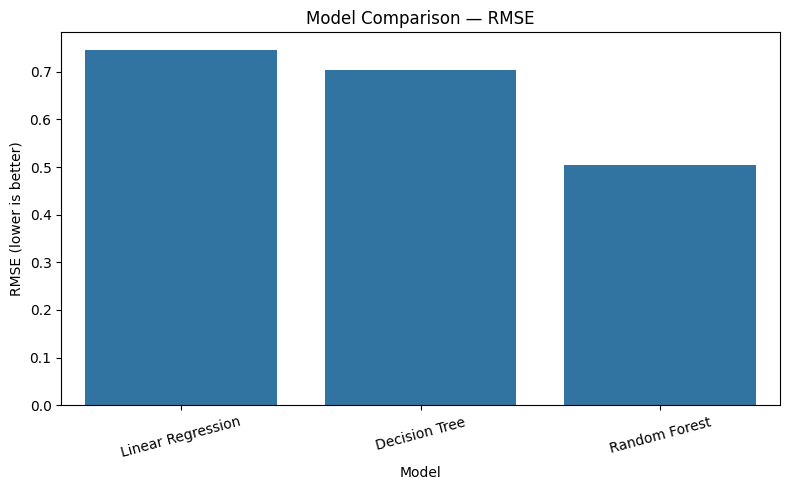

In [43]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=regression_results_df,
    x="Model",
    y="RMSE"
)

plt.title("Model Comparison — RMSE")
plt.ylabel("RMSE (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

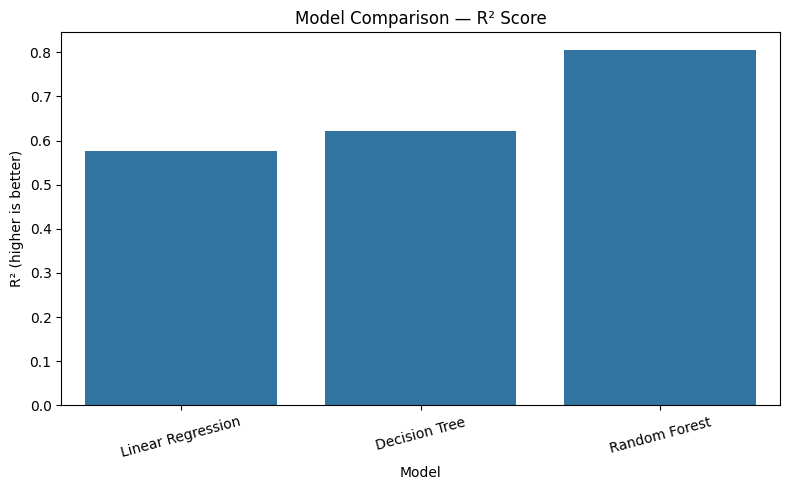

In [44]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=regression_results_df,
    x="Model",
    y="R2 Score"
)

plt.title("Model Comparison — R² Score")
plt.ylabel("R² (higher is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

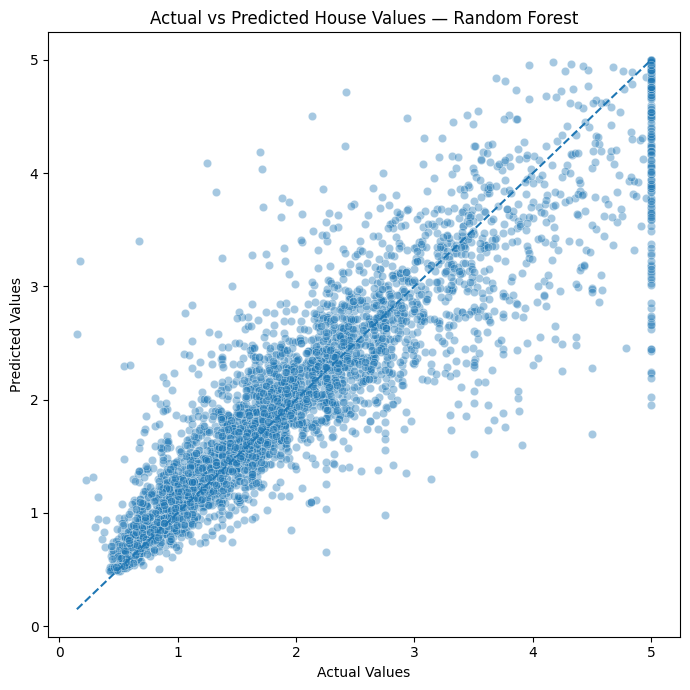

In [45]:
plt.figure(figsize=(7, 7))

sns.scatterplot(
    x=y_test,
    y=y_pred_rf_reg,
    alpha=0.4
)

min_value = min(y_test.min(), y_pred_rf_reg.min())
max_value = max(y_test.max(), y_pred_rf_reg.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted House Values — Random Forest")
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.tight_layout()
plt.show()

### Conclusion — California Housing Regression

In this experiment, Linear Regression, Decision Tree Regressor, and Random Forest Regressor were trained to predict median house values using the California Housing dataset. The dataset was divided into training and testing sets using an 80:20 split.

The models were evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the R² score. **Random Forest Regressor performed the best overall**, achieving the lowest MAE of **0.3275**, the lowest MSE of **0.2554**, the lowest RMSE of **0.5053**, and the highest R² score of **0.8051**. This indicates that the model explained approximately **80.51% of the variation** in median house values on the test set.

The Decision Tree Regressor achieved an R² score of **0.6221**, while Linear Regression achieved **0.5758**. Both models performed less effectively than Random Forest on this test set. These results suggest that Random Forest was better able to capture the complex relationships between the housing features and the target variable.

In conclusion, Random Forest Regressor was the most effective of the three models for this experiment. Further improvements could be explored through cross-validation, hyperparameter tuning, and residual analysis to assess the model's reliability and identify potential prediction errors.